In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 3.1 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
import os
import pandas as pd
from IPython.display import display
from ultralytics import YOLO

data_yaml = "/kaggle/input/datasets/ilhamibnuahmad/leaf-detection-dataset/data.yaml"
model_name = "yolo26n.pt"
epoch_list = [50]

comparison_rows = []
project_dir = "/kaggle/working/runs/detect"

for ep in epoch_list:
    run_name = f"train_ep{ep}"
    print(f"\n=== Training untuk epoch {ep} ===")

    exp_model = YOLO(model_name)
    exp_model.train(
        data=data_yaml,
        epochs=ep,
        imgsz=640,
        project=project_dir,
        name=run_name,
        exist_ok=True,
        verbose=False
    )

    val_result = exp_model.val(data=data_yaml, split="val", verbose=False)
    result_dict = val_result.results_dict

    precision = float(result_dict.get("metrics/precision(B)", result_dict.get("metrics/precision", 0.0)))
    recall = float(result_dict.get("metrics/recall(B)", result_dict.get("metrics/recall", 0.0)))
    map50 = float(result_dict.get("metrics/mAP50(B)", result_dict.get("metrics/mAP50", 0.0)))
    map50_95 = float(result_dict.get("metrics/mAP50-95(B)", result_dict.get("metrics/mAP50-95", 0.0)))

    best_path = os.path.join(project_dir, run_name, "weights", "best.pt")
    comparison_rows.append({
        "Epoch": ep,
        "Akurasi (%)": round(precision * 100, 2),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "MAP50": round(map50, 3),
        "MAP50-95": round(map50_95, 3),
        "Best Model Path": best_path,
    })

df_epoch_comparison = pd.DataFrame(comparison_rows).sort_values("Epoch").reset_index(drop=True)
display(df_epoch_comparison)

best_idx = df_epoch_comparison["MAP50-95"].idxmax()
best_epoch = int(df_epoch_comparison.loc[best_idx, "Epoch"])
best_model_path = df_epoch_comparison.loc[best_idx, "Best Model Path"]

print(f"\nEpoch terbaik (berdasarkan MAP50-95): {best_epoch}")
print(f"Best model path: {best_model_path}")

# Pakai model terbaik untuk evaluasi dan inferensi selanjutnya.
model = YOLO(best_model_path)


=== Training untuk epoch 50 ===
Ultralytics 8.4.165 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/ilhamibnuahmad/leaf-detection-dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_sca

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.96G     0.7367      2.037    0.01417          3        640: 100% ━━━━━━━━━━━━ 153/153 6.9it/s 22.3s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.7it/s 0.4s0.7s
                   all         64         64      0.966      0.938      0.979      0.832

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      2.96G     0.8165      1.161     0.0158          3        640: 100% ━━━━━━━━━━━━ 153/153 6.8it/s 22.6s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 5.0it/s 0.4s0.6s
                   all         64         64      0.997      0.984      0.992      0.868

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      2.96G     0.7971     0.8285    0.01569          5        640: 100% ━━━━━━━━━━━━ 153/153 6.8it/s 22.5s0.1s
                 Class     Images  In

,Epoch,Akurasi (%),Precision,Recall,MAP50,MAP50-95,Best Model Path
0,50,99.9,0.999,1.0,0.995,0.991,/kaggle/working/runs/detect/train_ep50/weights...



Epoch terbaik (berdasarkan MAP50-95): 50
Best model path: /kaggle/working/runs/detect/train_ep50/weights/best.pt


,Epoch,Akurasi (%),Precision,Recall,MAP50,MAP50-95,Best Model Path
0,50,99.9,0.999,1.0,0.995,0.991,/kaggle/working/runs/detect/train_ep50/weights...


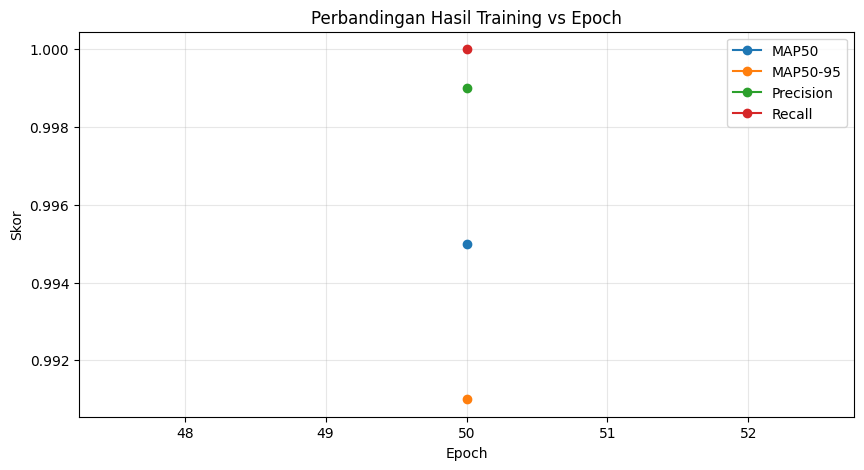

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display

# Ranking hasil eksperimen epoch (terbaik di atas).
df_rank = df_epoch_comparison.sort_values("MAP50-95", ascending=False).reset_index(drop=True)
display(df_rank)

# Grafik perbandingan metrik antar-epoch.
plt.figure(figsize=(10, 5))
plt.plot(df_epoch_comparison["Epoch"], df_epoch_comparison["MAP50"], marker="o", label="MAP50")
plt.plot(df_epoch_comparison["Epoch"], df_epoch_comparison["MAP50-95"], marker="o", label="MAP50-95")
plt.plot(df_epoch_comparison["Epoch"], df_epoch_comparison["Precision"], marker="o", label="Precision")
plt.plot(df_epoch_comparison["Epoch"], df_epoch_comparison["Recall"], marker="o", label="Recall")
plt.title("Perbandingan Hasil Training vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Skor")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [5]:
import pandas as pd
from ultralytics import YOLO
from IPython.display import display

# Pastikan evaluasi split memakai model terbaik dari eksperimen epoch.
if "best_model_path" in globals():
    model = YOLO(best_model_path)

split_mapping = [
    ("train", "Data Training"),
    ("val", "Data Validation"),
    ("test", "Data Testing"),
]

rows = []
for split, label in split_mapping:
    result = model.val(data=data_yaml, split=split, verbose=False)
    result_dict = result.results_dict

    precision = float(result_dict.get("metrics/precision(B)", result_dict.get("metrics/precision", 0.0)))
    recall = float(result_dict.get("metrics/recall(B)", result_dict.get("metrics/recall", 0.0)))
    map50 = float(result_dict.get("metrics/mAP50(B)", result_dict.get("metrics/mAP50", 0.0)))
    map50_95 = float(result_dict.get("metrics/mAP50-95(B)", result_dict.get("metrics/mAP50-95", 0.0)))

    rows.append({
        "Epoch Terbaik": best_epoch if "best_epoch" in globals() else "-",
        "Data": label,
        "Akurasi": f"{precision * 100:.2f}%",
        "Precision": f"{precision:.3f}",
        "Recall": f"{recall:.3f}",
        "MAP50": f"{map50:.3f}",
        "MAP50-95": f"{map50_95:.3f}",
    })

df_hasil = pd.DataFrame(rows)
display(df_hasil)

Ultralytics 8.4.165 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 35.4±15.9 MB/s, size: 47.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/ilhamibnuahmad/leaf-detection-dataset/train/labels... 2434 images, 55 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2434/2434 592.8it/s 4.1s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ilhamibnuahmad/leaf-detection-dataset/train is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 153/153 7.7it/s 19.8s0.1s
                   all       2434       2448       0.98      0.981      0.991      0.966
Speed: 0.9ms preprocess, 3.6ms inference, 0.0ms loss, 0.9ms pos

,Epoch Terbaik,Data,Akurasi,Precision,Recall,MAP50,MAP50-95
0,50,Data Training,98.00%,0.980,0.981,0.991,0.966
1,50,Data Validation,99.90%,0.999,1.000,0.995,0.991
2,50,Data Testing,99.16%,0.992,0.986,0.992,0.970


In [6]:
!zip -r leaf.zip /kaggle/working

  adding: kaggle/working/ (stored 0%)
  adding: kaggle/working/yolo26n.pt (deflated 11%)
  adding: kaggle/working/runs/ (stored 0%)
  adding: kaggle/working/runs/detect/ (stored 0%)
  adding: kaggle/working/runs/detect/val-3/ (stored 0%)
  adding: kaggle/working/runs/detect/val-3/val_batch0_pred.jpg (deflated 6%)
  adding: kaggle/working/runs/detect/val-3/val_batch0_labels.jpg (deflated 6%)
  adding: kaggle/working/runs/detect/val-3/val_batch2_pred.jpg (deflated 6%)
  adding: kaggle/working/runs/detect/val-3/val_batch1_pred.jpg (deflated 7%)
  adding: kaggle/working/runs/detect/val-3/val_batch1_labels.jpg (deflated 7%)
  adding: kaggle/working/runs/detect/val-3/BoxR_curve.png (deflated 19%)
  adding: kaggle/working/runs/detect/val-3/confusion_matrix.png (deflated 39%)
  adding: kaggle/working/runs/detect/val-3/BoxF1_curve.png (deflated 17%)
  adding: kaggle/working/runs/detect/val-3/confusion_matrix_normalized.png (deflated 40%)
  adding: kaggle/working/runs/detect/val-3/BoxPR_curve.pn

In [7]:
from IPython.display import FileLink
FileLink(r'leaf.zip')

/kaggle/working/leaf.zip